# Which family of languages has the highest density of speakers?

In [2]:
import pandas as pd
africa = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-01-13/africa.csv')

In [3]:
family_density = (
    africa.groupby("family")
    .agg(
        total_speakers=("native_speakers", "sum"),
        n_languages=("language", "nunique")
    )
    .assign(
        speaker_density=lambda x: x["total_speakers"] / x["n_languages"]
    )
    .sort_values("speaker_density", ascending=False)
)

print(family_density)

               total_speakers  n_languages  speaker_density
family                                                     
Afroasiatic        2369939800           17     1.394082e+08
Kongo-based          26000000            1     2.600000e+07
Indo-European       101665300            4     2.541632e+07
Austronesian         18000000            1     1.800000e+07
Niger–Congo        1353163982          383     3.533065e+06
Nilo-Saharan        111091000           70     1.587014e+06
Portuguese             871000            1     8.710000e+05
French                1173000            2     5.865000e+05
English                866000            2     4.330000e+05
Ubangian              1590000            6     2.650000e+05
Mande                  230000            1     2.300000e+05
Afro-Asiatic           714300            4     1.785750e+05
Arabic-based           350000            2     1.750000e+05
Khoe–Kwadi             259500            4     6.487500e+04
Kxʼa                   107500           

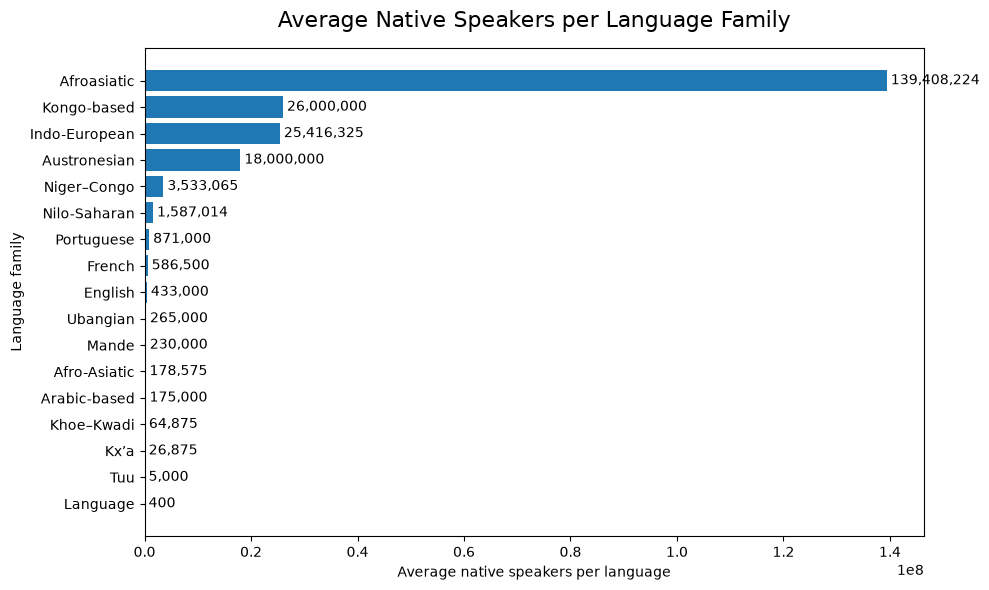

In [4]:
import matplotlib.pyplot as plt

plot_data = family_density.sort_values("speaker_density")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_data.index,
    plot_data["speaker_density"]
)

ax.set_title(
    "Average Native Speakers per Language Family",
    fontsize=16,
    pad=15
)
ax.set_xlabel("Average native speakers per language")
ax.set_ylabel("Language family")

for bar in bars:
    value = bar.get_width()
    ax.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f" {value:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

The family of languages with the highest density of speakers is Afroasiatic.